# Lab L3.3 · Card-fraud detection on 1.5M transactions — velocity features, decision trees and random forests
**Horizon Gulf Bank · Project MIZAN** · CAIP AIP-210 · Certified AI Practitioner · Day 3 · ⏱ 80 min · **Level 3 · Complete solution**

Engineer real-time-safe velocity features at scale, grow and prune interpretable trees, beat them with a random forest, and evaluate against the fraud team’s daily alert budget.

### Scenario
**Horizon Gulf Bank (HGB)** is a fictional UAE retail bank with 250,000 customers. Its Board approved **Project MIZAN** — an AI decisioning platform covering credit, fraud, collateral valuation, cash logistics, customer retention and document automation. You are a junior ML practitioner in the MIZAN squad.

HGB’s rules engine ("block foreign e-commerce > AED 5,000") catches too little fraud and annoys customers. The Fraud Operations team can manually review **0.5% of transactions** per day. Your model must rank transactions so that the reviewed 0.5% contains as much fraud — and as many dirhams of fraud — as possible, and its logic must be explainable to auditors.

**Progressive architecture:** your feature table feeds the SVM and neural-network labs (Day 4); your feature function is deployed and monitored on Day 5.

### Objectives
- Build per-card velocity features with `groupby` + time-based `rolling` on 1.5M rows, using only past information
- Use an out-of-time split (train Apr–Jul, validate Aug, test Sep)
- Read decision-tree rules; compare Gini vs entropy
- Control over-fitting with depth, leaf size and cost-complexity pruning
- Train a random forest on an undersampled set and understand the effect on probabilities
- Compare impurity vs permutation importance; evaluate precision/recall at a fixed alert budget

In [1]:
# ── Project MIZAN course setup ─ run this cell first ──────────────────────────
from pathlib import Path
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the course root (the folder that contains data/generate_data.py) from wherever this notebook lives
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "generate_data.py").exists())
DATA = ROOT / "data"          # raw synthetic datasets (read-only)
CKPT = ROOT / "checkpoints"   # hand-off artefacts between labs (lets you start any lab fresh)
CKPT.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": .3})
RNG = 42
print("Course root:", ROOT)

Course root: C:\Users\Pushkar\Downloads\CAIP-AIP210-FINANCIAL-SERVICES-TRAINER-PACK\CAIP-AIP210-TopTier-Courseware


## Step 1 · Load 1.5M transactions efficiently and split in time

**Why this matters.** Fraud patterns evolve, so the honest split is **out-of-time**. Loading with explicit dtypes keeps memory manageable and makes `groupby` fast.

In [2]:
tx = pd.read_csv(DATA / "card_transactions.csv.gz", parse_dates=["txn_ts"],
                 dtype={c: "category" for c in ["merchant_category", "channel", "merchant_country", "customer_home_emirate"]})
print(f"{len(tx):,} rows | {tx.memory_usage(deep=True).sum() / 1e6:,.0f} MB | fraud rate {tx.is_fraud.mean():.3%}")
print(tx.groupby("channel", observed=True).is_fraud.agg(["mean", "sum"]).sort_values("mean", ascending=False).round(4))
TRAIN_END, VALID_END = pd.Timestamp("2025-08-01"), pd.Timestamp("2025-09-01")

1,506,430 rows | 203 MB | fraud rate 0.427%
               mean   sum
channel                  
ATM          0.0155  1419
E-Commerce   0.0118  4391
Contactless  0.0010   620
POS_Chip     0.0000     0


## Step 2 · Velocity features — the fraud analyst’s secret weapon

**Why this matters.** A single transaction looks normal; **five in ten minutes on a new device abroad** does not. Velocity features summarise each card’s recent behaviour. Every one must use only the current and **earlier** transactions of that card, otherwise it leaks the future and cannot be computed at authorisation time.

In [3]:
def build_fraud_features(tx: pd.DataFrame) -> pd.DataFrame:
    """Per-card behavioural (velocity) features using ONLY each card's past and present — safe for real-time scoring."""
    tx = tx.sort_values(["card_id", "txn_ts"]).reset_index(drop=True)
    g = tx.groupby("card_id")
    tx["secs_since_prev"] = g.txn_ts.diff().dt.total_seconds().fillna(30 * 86400)
    roll = tx.set_index("txn_ts").groupby("card_id").amount_aed
    tx["txn_count_1h"] = roll.rolling("1h").count().to_numpy()
    r24 = roll.rolling("24h").agg(["count", "sum"])
    tx["txn_count_24h"], tx["amount_sum_24h"] = r24["count"].to_numpy(), r24["sum"].to_numpy()
    prior_mean = g.amount_aed.transform(lambda s: s.shift(1).expanding().mean())
    tx["amount_vs_card_mean"] = tx.amount_aed / prior_mean.fillna(tx.amount_aed.median())
    tx["is_new_country_for_card"] = (~tx.duplicated(["card_id", "merchant_country"])).astype(int)
    tx["is_new_mcc_for_card"] = (~tx.duplicated(["card_id", "merchant_category"])).astype(int)
    tx["card_txn_index"] = g.cumcount()
    tx["hour"] = tx.txn_ts.dt.hour
    tx["is_night"] = tx.hour.between(0, 5).astype(int)
    tx["is_international"] = (tx.merchant_country != "AE").astype(int)
    tx["amount_to_salary"] = tx.amount_aed / tx.customer_monthly_salary_aed
    tx["log_amount"] = np.log1p(tx.amount_aed)
    return tx.sort_values("txn_ts").reset_index(drop=True)

NUMF = ["log_amount", "merchant_risk_score", "is_3ds_authenticated", "is_new_device", "distance_from_home_km", "customer_age",
        "card_tenure_months", "secs_since_prev", "txn_count_1h", "txn_count_24h", "amount_sum_24h", "amount_vs_card_mean",
        "is_new_country_for_card", "is_new_mcc_for_card", "card_txn_index", "hour", "is_night", "is_international", "amount_to_salary"]
CATF = ["merchant_category", "channel"]

In [4]:
t0 = time.perf_counter()
tf = build_fraud_features(tx)
tf["split"] = np.select([tf.txn_ts < TRAIN_END, tf.txn_ts < VALID_END], ["train", "valid"], "test")
print(f"features built in {time.perf_counter() - t0:.0f}s"); print(tf.split.value_counts())
tf.groupby("is_fraud")[["txn_count_1h", "secs_since_prev", "amount_vs_card_mean", "is_new_country_for_card"]].median()

features built in 11s
split
train    1004221
valid     255150
test      247059
Name: count, dtype: int64


,txn_count_1h,secs_since_prev,amount_vs_card_mean,is_new_country_for_card
is_fraud,,,,
0,1.0,289180.0,0.446951,0.0
1,3.0,605.0,1.903097,0.0


> **Think like a practitioner.** `is_new_country_for_card` is 1 for every card’s first transaction in our data window. Why is that a *cold-start* bias, and how would production avoid it?

## Step 3 · An interpretable decision tree — and its rules

**Why this matters.** Trees need no scaling and handle interactions natively. A depth-3 tree is a set of human-readable rules your auditors can review. Missing values for *not-applicable* fields (3DS on POS) are encoded as −1 so the tree can split on ‘not e-commerce’.

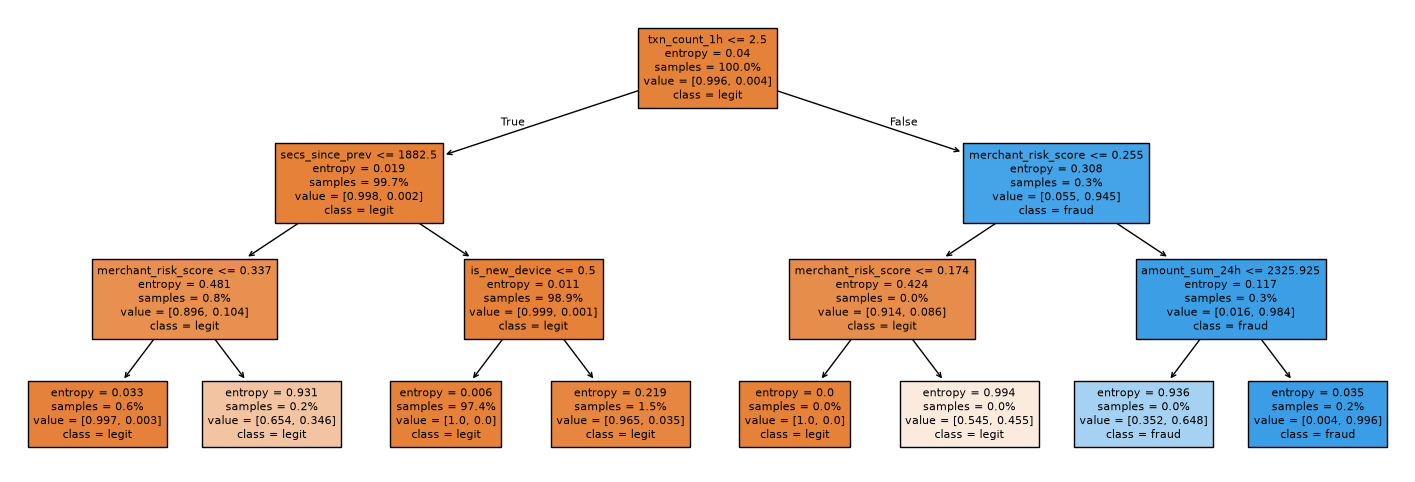

|--- txn_count_1h <= 2.50
|   |--- secs_since_prev <= 1882.50
|   |   |--- merchant_risk_score <= 0.34
|   |   |   |--- class: 0
|   |   |--- merchant_risk_score >  0.34
|   |   |   |--- class: 0
|   |--- secs_since_prev >  1882.50
|   |   |--- is_new_device <= 0.50
|   |   |   |--- class: 0
|   |   |--- is_new_device >  0.50
|   |   |   |--- class: 0
|--- txn_count_1h >  2.50
|   |--- merchant_risk_score <= 0.26
|   |   |--- merchant_risk_score <= 0.17
|   |   |   |--- class: 0
|   |   |--- merchant_risk_score >  0.17
|   |   |   |--- class: 0
|   |--- merchant_risk_score >  0.26
|   |   |--- amount_sum_24h <= 2325.93
|   |   |   |--- class: 1
|   |   |--- amount_sum_24h >  2325.93
|   |   |   |--- class: 1



,precision@0.5%,recall@0.5%,AED_caught_share,PR_AUC
tree depth3 gini,0.685,0.702,0.703,0.725
tree depth3 entropy,0.729,0.748,0.743,0.745


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import average_precision_score
prep = ColumnTransformer([("num", SimpleImputer(strategy="constant", fill_value=-1), NUMF),
                          ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATF)], verbose_feature_names_out=False)
tr, va, te = (tf[tf.split == s] for s in ["train", "valid", "test"])
FEATS = NUMF + CATF

def at_budget(y, p, amount, budget=0.005) -> dict:
    y, amount = np.asarray(y), np.asarray(amount)
    top = np.argsort(-p)[: int(len(p) * budget)]
    return {"precision@0.5%": y[top].mean(), "recall@0.5%": y[top].sum() / y.sum(),
            "AED_caught_share": (amount[top] * y[top]).sum() / (amount * y).sum(), "PR_AUC": average_precision_score(y, p)}

board = {}
for crit in ["gini", "entropy"]:
    t3 = Pipeline([("prep", prep), ("dt", DecisionTreeClassifier(max_depth=3, criterion=crit, random_state=RNG))]).fit(tr[FEATS], tr.is_fraud)
    board[f"tree depth3 {crit}"] = at_budget(va.is_fraud, t3.predict_proba(va[FEATS])[:, 1], va.amount_aed)
plt.figure(figsize=(18, 6)); plot_tree(t3.named_steps["dt"], feature_names=FEATS, filled=True, proportion=True, fontsize=8, class_names=["legit", "fraud"]); plt.show()
print(export_text(t3.named_steps["dt"], feature_names=FEATS, decimals=2))
pd.DataFrame(board).T.round(3)

> **Think like a practitioner.** Translate the highest-fraud leaf into an English rule the Fraud Operations team could implement tomorrow.

## Step 4 · Depth, leaf size and cost-complexity pruning

**Why this matters.** An unlimited tree memorises 1M training rows — perfect on train, worse on August. We sweep `max_depth`, then use **cost-complexity pruning** (`ccp_alpha`), which removes branches whose impurity reduction does not justify their complexity.

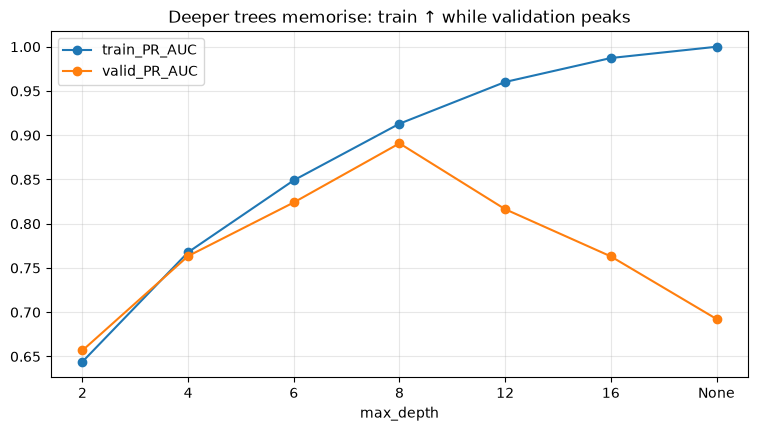

In [6]:
Xtr, Xva = prep.fit_transform(tr[FEATS]), prep.transform(va[FEATS])
depths, rec = [2, 4, 6, 8, 12, 16, None], []
for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=1, random_state=RNG).fit(Xtr, tr.is_fraud)
    rec.append((str(d), average_precision_score(tr.is_fraud, dt.predict_proba(Xtr)[:, 1]), average_precision_score(va.is_fraud, dt.predict_proba(Xva)[:, 1])))
rec = pd.DataFrame(rec, columns=["max_depth", "train_PR_AUC", "valid_PR_AUC"]).set_index("max_depth")
rec.plot(marker="o", title="Deeper trees memorise: train ↑ while validation peaks"); plt.show()
best_depth = rec.valid_PR_AUC.idxmax(); best_depth = None if best_depth == "None" else int(best_depth)
dt_best = DecisionTreeClassifier(max_depth=best_depth, random_state=RNG).fit(Xtr, tr.is_fraud)
board[f"tree depth={best_depth}"] = at_budget(va.is_fraud, dt_best.predict_proba(Xva)[:, 1], va.amount_aed)

In [7]:
from sklearn.model_selection import train_test_split
Xs_, _, ys_, _ = train_test_split(Xtr, tr.is_fraud, train_size=150_000, stratify=tr.is_fraud, random_state=RNG)
path = DecisionTreeClassifier(random_state=RNG).cost_complexity_pruning_path(Xs_, ys_)
alphas = np.quantile(path.ccp_alphas[path.ccp_alphas > 0], [0.5, 0.7, 0.8, 0.9, 0.95, 0.97, 0.99, 0.995])
pruned = [(a, DecisionTreeClassifier(ccp_alpha=a, random_state=RNG).fit(Xs_, ys_)) for a in alphas]
scores_ = [(a, m.tree_.node_count, average_precision_score(va.is_fraud, m.predict_proba(Xva)[:, 1])) for a, m in pruned]
display(pd.DataFrame(scores_, columns=["ccp_alpha", "nodes", "valid_PR_AUC"]).round(6))
a_best, m_best = max(pruned, key=lambda am: average_precision_score(va.is_fraud, am[1].predict_proba(Xva)[:, 1]))
board["tree pruned (150k)"] = at_budget(va.is_fraud, m_best.predict_proba(Xva)[:, 1], va.amount_aed)
pd.DataFrame(board).T.round(3)

,ccp_alpha,nodes,valid_PR_AUC
0,0.000011,153,0.718592
1,0.000018,91,0.796594
2,0.000021,63,0.820096
3,0.000034,31,0.812016
4,0.000081,17,0.775949
5,0.000162,9,0.676314
6,0.000630,3,0.562709
7,0.002660,3,0.562709


,precision@0.5%,recall@0.5%,AED_caught_share,PR_AUC
tree depth3 gini,0.685,0.702,0.703,0.725
tree depth3 entropy,0.729,0.748,0.743,0.745
tree depth=8,0.838,0.859,0.855,0.891
tree pruned (150k),0.808,0.829,0.830,0.820


> **Think like a practitioner.** Which tree would you show an auditor, and which would you deploy? Can it be the same one?

## Step 5 · Random forest on an undersampled training set

**Why this matters.** A **random forest** averages many deep trees, each grown on a bootstrap sample with random feature subsets — reducing variance. With 0.4% fraud, keeping all fraud and ~25% of legitimate transactions speeds training 4× with little loss of ranking power. Undersampling inflates probabilities; ranking-based metrics (budget, PR-AUC) are unaffected, and we correct the probabilities explicitly.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
legit = tr[tr.is_fraud == 0]
tr_u = pd.concat([tr[tr.is_fraud == 1], legit.sample(250_000, random_state=RNG)])
beta = 250_000 / len(legit)                      # sampling rate of the majority class
t0 = time.perf_counter()
rf = Pipeline([("prep", prep), ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=10, max_features="sqrt",
                                                             n_jobs=-1, random_state=RNG))]).fit(tr_u[FEATS], tr_u.is_fraud)
print(f"RF trained on {len(tr_u):,} rows in {time.perf_counter() - t0:.0f}s")
p_rf_s = rf.predict_proba(va[FEATS])[:, 1]
board["random forest"] = at_budget(va.is_fraud, p_rf_s, va.amount_aed)
lr = Pipeline([("prep", prep), ("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=2000))]).fit(tr_u[FEATS], tr_u.is_fraud)
board["logistic (same features)"] = at_budget(va.is_fraud, lr.predict_proba(va[FEATS])[:, 1], va.amount_aed)
p_rf = beta * p_rf_s / (beta * p_rf_s - p_rf_s + 1)
print(f"mean predicted fraud prob — raw: {p_rf_s.mean():.4f} | corrected: {p_rf.mean():.4f} | actual: {va.is_fraud.mean():.4f}")
pd.DataFrame(board).T.sort_values("PR_AUC", ascending=False).round(3)

RF trained on 254,325 rows in 14s


mean predicted fraud prob — raw: 0.0065 | corrected: 0.0042 | actual: 0.0049


,precision@0.5%,recall@0.5%,AED_caught_share,PR_AUC
random forest,0.872,0.895,0.901,0.945
logistic (same features),0.856,0.879,0.886,0.928
tree depth=8,0.838,0.859,0.855,0.891
tree pruned (150k),0.808,0.829,0.830,0.820
tree depth3 entropy,0.729,0.748,0.743,0.745
tree depth3 gini,0.685,0.702,0.703,0.725


> **Think like a practitioner.** Bagging reduces variance. Which ensemble family reduces *bias* instead? (boosting — HistGradientBoosting/XGBoost)

## Step 6 · Which features drive the forest? Impurity vs permutation importance

**Why this matters.** Impurity importance is computed on training data and favours high-cardinality continuous features. **Permutation importance** measures how much *validation* PR-AUC drops when a feature is shuffled — slower but more trustworthy, and model-agnostic.

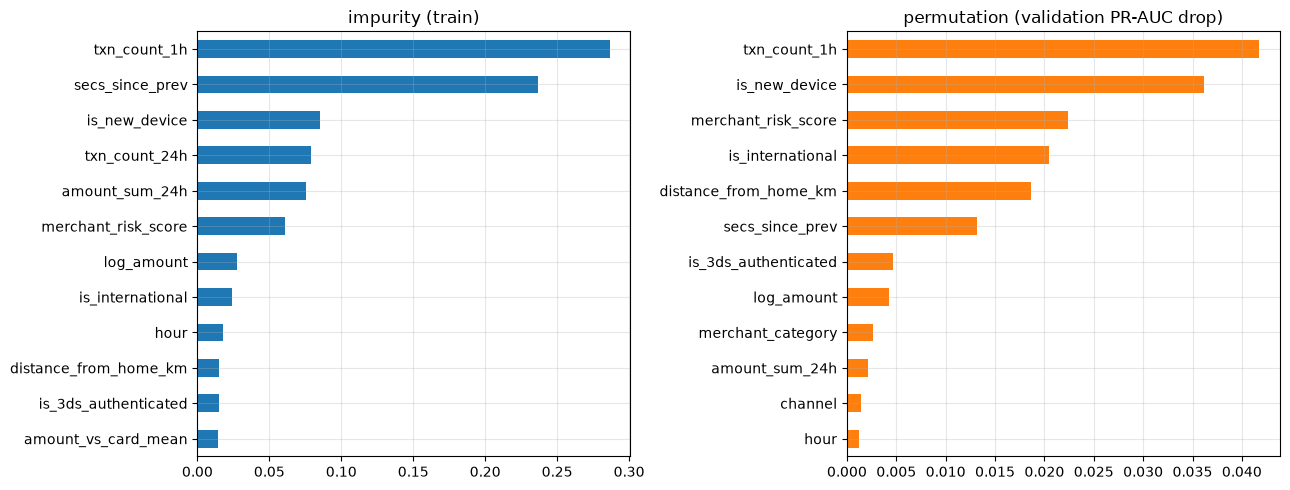

In [9]:
from sklearn.inspection import permutation_importance
imp = pd.Series(rf.named_steps["rf"].feature_importances_, index=FEATS).sort_values()
va_s = pd.concat([va[va.is_fraud == 1], va[va.is_fraud == 0].sample(40_000, random_state=RNG)])
perm = permutation_importance(rf, va_s[FEATS], va_s.is_fraud, scoring="average_precision", n_repeats=3, random_state=RNG, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=FEATS).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 5)); imp.tail(12).plot.barh(ax=ax[0], title="impurity (train)"); perm_s.tail(12).plot.barh(ax=ax[1], color="tab:orange", title="permutation (validation PR-AUC drop)")
plt.tight_layout(); plt.show()

> **Think like a practitioner.** Two features are highly correlated. What happens to *both* their permutation importances, and why?

## Step 7 · Test-month evaluation and hand-off

**Why this matters.** September is the untouched test month. We report the metrics the Fraud Ops head cares about, then save the feature table (Day 4 reads it), the forest and the metrics.

In [10]:
import joblib, json
p_te = rf.predict_proba(te[FEATS])[:, 1]
m_te = at_budget(te.is_fraud, p_te, te.amount_aed)
days = te.txn_ts.dt.normalize().nunique()
print({k: round(v, 3) for k, v in m_te.items()}, f"| alerts/day ≈ {int(len(te) * 0.005 / days)}")
keep = ["txn_id", "txn_ts", "card_id", "customer_id", "amount_aed", "merchant_country", "is_fraud", "split"] + FEATS
tf[keep].to_parquet(CKPT / "card_features.parquet", index=False)
joblib.dump(rf, CKPT / "fraud_rf.joblib", compress=3)
(CKPT / "fraud_metrics.json").write_text(json.dumps({"valid": {k: float(v) for k, v in board["random forest"].items()},
    "test": {k: float(v) for k, v in m_te.items()}, "features": FEATS, "undersample_beta": beta, "budget": 0.005}, indent=2))
print("saved card_features.parquet, fraud_rf.joblib, fraud_metrics.json")

{'precision@0.5%': np.float64(0.645), 'recall@0.5%': np.float64(0.923), 'AED_caught_share': np.float64(0.939), 'PR_AUC': 0.932} | alerts/day ≈ 41


saved card_features.parquet, fraud_rf.joblib, fraud_metrics.json


> **Think like a practitioner.** The fraud team asks to raise the budget to 1%. Without retraining, how do you estimate the extra fraud caught and the extra false alerts?

## ✅ Lab complete
The fraud model ranks 0.5% of traffic containing most of the fraud. **Tomorrow:** SVMs and neural networks — can they do better?